# 🏙️ PropertyIQ: A 20-Minute Data Visualization Sprint
### Unit 1 — Foundations of Visualization, Data Interpretation (UE24CS342AA9)

**Dataset:** [Melbourne Housing Snapshot](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot) (Kaggle)

---

## 📖 The Scenario

You have just joined **PropertyIQ**, a Melbourne-based real-estate analytics startup, as a **junior data analyst**.

Tomorrow morning, your **Head of Sales** is meeting a client — a property investment fund — and needs a short briefing built from the `melb_data.csv` housing snapshot. She has given you **20 minutes** to turn the raw data into something she can actually present.

She says:

> *"I don't want a data dump. I want to walk in, show three good visuals, and leave the client with one clear takeaway. Make sure the charts are the right *type*, saved in the right *format*, and that the design doesn't get in the way of the message."*

This activity walks you through exactly the workflow described in the lecture: **understand the context → choose the right chart → choose the right file format → separate content from design → tell the story.**




## Part 0 — Setup (1 min)

1. Download **`melb_data.csv`** from the [Kaggle dataset page](https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot).
2. Place it in the **same folder** as this notebook.
3. Run the cell below.

*(If the file isn't found, the cell will auto-generate a small synthetic stand-in with the same columns, so you can still complete the activity — just swap in the real CSV later.)*


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

np.random.seed(42)

DATA_PATH = "melb_data.csv"

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded real dataset: {df.shape[0]} rows, {df.shape[1]} columns")
else:
    print("melb_data.csv not found — generating a small synthetic stand-in so you can still run the activity.")
    n = 600
    regions = ["Northern Metropolitan", "Western Metropolitan", "Southern Metropolitan",
               "Eastern Metropolitan", "South-Eastern Metropolitan"]
    types = ["h", "u", "t"]  # house, unit, townhouse
    df = pd.DataFrame({
        "Suburb": np.random.choice(["Richmond", "Brunswick", "Carlton", "Footscray",
                                     "St Kilda", "Fitzroy", "Camberwell"], n),
        "Rooms": np.random.randint(1, 6, n),
        "Type": np.random.choice(types, n, p=[0.6, 0.3, 0.1]),
        "Price": np.random.lognormal(mean=13.5, sigma=0.4, size=n).round(-3),
        "Distance": np.round(np.random.exponential(8, n), 1),
        "Landsize": np.random.exponential(400, n).round(0),
        "BuildingArea": np.random.normal(150, 50, n).clip(30, 500).round(0),
        "YearBuilt": np.random.randint(1900, 2018, n),
        "Regionname": np.random.choice(regions, n),
        "Bathroom": np.random.randint(1, 4, n),
        "Car": np.random.randint(0, 4, n),
    })

df.head()


Loaded real dataset: 13580 rows, 20 columns


,Date,Suburb,Rooms,Type,Method,SellerG,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount,Price
0,23/09/2017,Aberfeldie,5,h,S,Rendina,7.5,3040,5,4,4.0,730,373.0,2014.0,NaN,-37.75950,144.89427,Western Metropolitan,1543,1830000
1,23/09/2017,Airport West,3,h,S,Brad,10.4,3042,3,1,2.0,551,96.0,1950.0,NaN,-37.72739,144.88235,Western Metropolitan,3464,850000
2,23/09/2017,Airport West,3,h,S,Harcourts,10.4,3042,3,2,2.0,593,NaN,NaN,NaN,-37.72057,144.87558,Western Metropolitan,3464,860000
3,23/09/2017,Albanvale,3,h,S,Bells,14.0,3021,3,1,2.0,619,NaN,NaN,NaN,-37.74521,144.76863,Western Metropolitan,1899,565000
4,23/09/2017,Albert Park,3,h,VB,Cayzer,3.0,3206,3,2,NaN,137,125.0,1890.0,NaN,-37.84388,144.95303,Southern Metropolitan,3280,2100000


## Part 1 — Understand the Context (3 min)

> *"Good data visualization begins with understanding the problem, not by choosing a chart."*

Recall the lecture's distinction:

| Exploratory Analysis | Explanatory Analysis |
|---|---|
| Explores data to discover patterns | Communicates a clear insight |
| Multiple hypotheses tested | One key message emphasized |
| Used by the analyst | Designed for the audience |

**Run the cell below** to get a quick feel for the data (this is *exploratory* — you're doing it for yourself, not the client).


In [2]:
df.info()
df.describe(include="all").T.head(10)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           13580 non-null  object 
 1   Suburb         13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Method         13580 non-null  object 
 5   SellerG        13580 non-null  object 
 6   Distance       13580 non-null  float64
 7   Postcode       13580 non-null  int64  
 8   Bedroom2       13580 non-null  int64  
 9   Bathroom       13580 non-null  int64  
 10  Car            13518 non-null  float64
 11  Landsize       13580 non-null  int64  
 12  BuildingArea   7130 non-null   float64
 13  YearBuilt      8205 non-null   float64
 14  CouncilArea    12211 non-null  object 
 15  Lattitude      13580 non-null  float64
 16  Longtitude     13580 non-null  float64
 17  Regionname     13580 non-null  object 
 18  Proper

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,13580,58,27/05/2017,473,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Suburb,13580,314,Reservoir,359,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rooms,13580.0,NaN,NaN,NaN,2.937997,0.955748,1.0,2.0,3.0,3.0,10.0
Type,13580,3,h,9449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Method,13580,5,S,9022,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SellerG,13580,268,Nelson,1565,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Distance,13580.0,NaN,NaN,NaN,10.137776,5.868725,0.0,6.1,9.2,13.0,48.1
Postcode,13580.0,NaN,NaN,NaN,3105.301915,90.676964,3000.0,3044.0,3084.0,3148.0,3977.0
Bedroom2,13580.0,NaN,NaN,NaN,2.914728,0.965921,0.0,2.0,3.0,3.0,20.0
Bathroom,13580.0,NaN,NaN,NaN,1.534242,0.691712,0.0,1.0,1.0,2.0,8.0


### ✍️ Your turn (fill in the markdown cell below)

Answer in 1–2 sentences each:

1. **Who** is the audience for the visuals you're about to build (recall the scenario)?
2. Is the work you just did (`df.info()`, `df.describe()`) *exploratory* or *explanatory*? Why?
3. What is **one** question that the investment fund client would actually care about?


**Your answers:**

1. **Audience:** The Head of Sales, and through her the client — a property **investment fund**. They are not analysts, so they will not read code, column names or summary tables. They want three clear visuals and one takeaway they can act on. This means the charts must be self-explanatory without me standing next to them to narrate.

2. **Exploratory or explanatory, and why:** `df.info()` and `df.describe()` are **exploratory**. They are for *me* — I am checking the shape of the data (13,580 rows, 20 columns), which columns have missing values (`BuildingArea` and `YearBuilt` are badly incomplete, `Price` is complete) and whether the ranges are sane. Nobody in the client meeting would ever be shown this output; it tests many hypotheses at once instead of communicating one. It is the necessary step *before* explanatory work, not a deliverable.

3. **A question the client cares about:** *"Which Melbourne regions give us the best price entry point, and how much price variation should we expect within a region?"* An investment fund is deciding where to deploy capital, so they care about **relative price levels between regions** and the **risk/spread around those levels** — not about the average number of bathrooms.


## Part 2 — Choosing the Right Chart (7 min)

Recall the recommendation table from the lecture:

| Purpose | Recommended Chart |
|---|---|
| Compare categories | Bar Chart |
| Show trends | Line Chart |
| Show relationships | Scatter Plot |
| Show distributions | Histogram / Box Plot |
| Show proportions | Stacked Bar (limited categories) |

Your Head of Sales wants **three** visuals for the briefing. For each question below:
1. Write down which chart type is appropriate (and *why*, referencing the table).
2. Fill in the `# TODO` in the code to build it.

Avoid choosing a chart just because it "looks nice" — first identify what question it needs to answer.


### 2.1 — "How do average prices differ across regions?"

**Chart type:** *(bar / line / scatter / histogram / stacked bar)* → **Bar chart** (specifically a **horizontal** bar chart, `barh`)

**Why:** `Regionname` is a **categorical** variable with 8 discrete, unordered levels, and the question is explicitly *"how do they differ"* — that is a **comparison of categories**, which the lecture's table maps directly to a bar chart. Bars start from a common zero baseline, so the reader compares lengths, and length is one of the most accurately decoded visual channels. A line chart would be wrong because it implies a continuous ordering between regions that does not exist, and a pie chart would be wrong because these are averages, not parts of a whole that sum to 100%.

I chose **`barh`** over `bar` for one practical design reason: the region names are long (*"South-Eastern Metropolitan"*) and would collide or need rotating on a vertical x-axis. Horizontal bars let the labels sit flat and stay readable. Sorting the bars by value (via `.sort_values()`) also does real work here — it turns the chart into an instant ranking, so the audience sees the best and worst region without hunting.


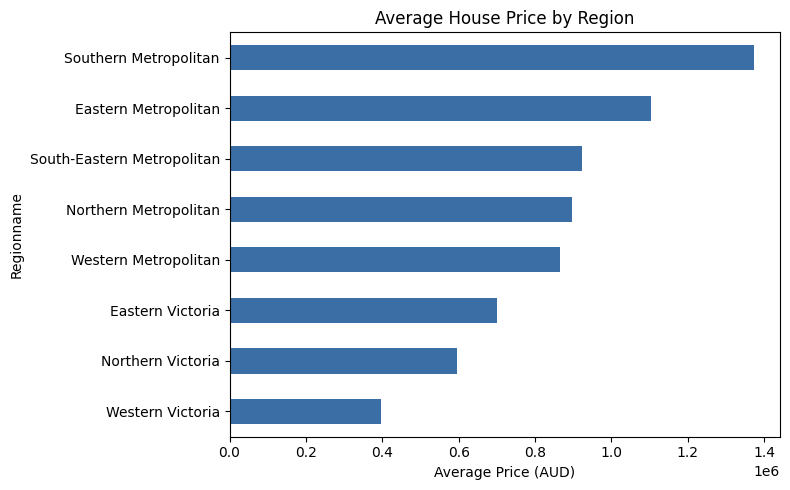

Average price by region (AUD millions):
Regionname
Western Victoria              0.398
Northern Victoria             0.595
Eastern Victoria              0.700
Western Metropolitan          0.866
Northern Metropolitan         0.898
South-Eastern Metropolitan    0.923
Eastern Metropolitan          1.104
Southern Metropolitan         1.373

Property count per region:
Regionname
Southern Metropolitan         4695
Northern Metropolitan         3890
Western Metropolitan          2948
Eastern Metropolitan          1471
South-Eastern Metropolitan     450
Eastern Victoria                53
Northern Victoria               41
Western Victoria                32


In [3]:
# Build a chart that compares average Price across Regionname
# Group by Regionname, take the mean Price, sort so the chart reads as a ranking

region_avg = df.groupby("Regionname")["Price"].mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))

# Categorical comparison -> BAR chart. "barh" keeps the long region names readable.
region_avg.plot(kind="barh", ax=ax, color="#3b6ea5")

ax.set_xlabel("Average Price (AUD)")
ax.set_title("Average House Price by Region")
plt.tight_layout()
plt.show()

# Print the underlying numbers so the written answers can cite real figures
print("Average price by region (AUD millions):")
print((region_avg / 1e6).round(3).to_string())
print("\nProperty count per region:")
print(df["Regionname"].value_counts().to_string())


### 2.2 — "Is there a relationship between land size and price?"

**Chart type:** *(bar / line / scatter / histogram / stacked bar)* → **Scatter plot**

**Why:** Both `Landsize` and `Price` are **continuous numeric** variables, and the question asks about a **relationship** between them — the lecture's table maps that case straight to a scatter plot. A scatter is the only one of these options that plots each property as its own point, so it preserves every individual observation and lets the shape of the cloud (or the absence of one) speak for itself. Binning either variable into a bar chart would destroy exactly the information the question is asking about.

`alpha=0.4` and `s=15` are **design** choices, not content ones: with 13,580 points the markers pile on top of each other, and semi-transparent small dots stop the dense region from turning into one solid black blob (overplotting).

**What it actually shows — and the honest answer:** essentially **no usable relationship**. The correlation across the raw data is only **r = 0.038**. The plot looks like a thin horizontal smear because a handful of rural properties (the largest is **433,014 sq m**) stretch the x-axis so far that 99% of the data is squashed against the left edge. There are also **1,939 rows with `Landsize` = 0**, which are apartments/units with no land title rather than genuine zero-area blocks. Restricting to plausible urban blocks (0 < Landsize < 2,000 sq m, n = 11,402) lifts the correlation only to **r = 0.195** — still weak. So the truthful message for the client is that in Melbourne **land size is a poor predictor of price; location does far more work**, which is precisely what Chart 2.1 shows.


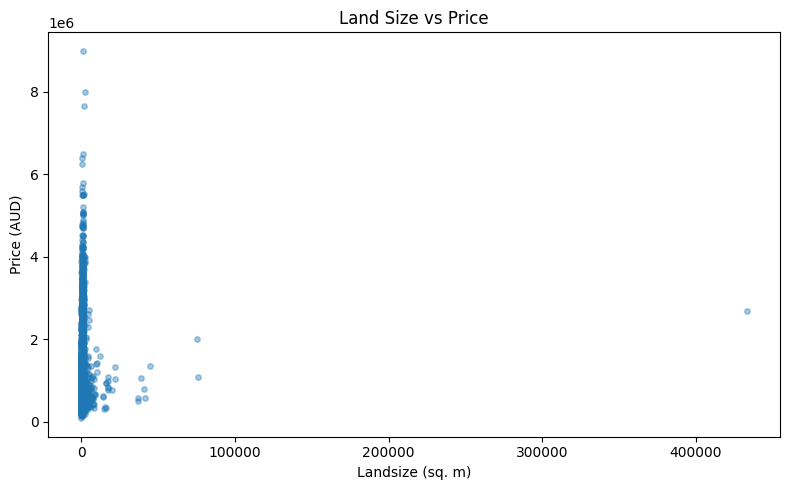

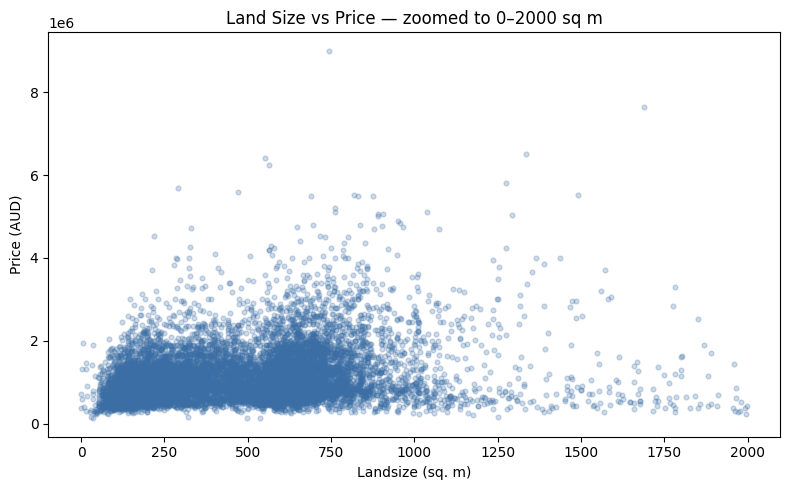

Correlation on all data      : r = 0.038
Correlation on 0-2000 sq m   : r = 0.195  (n = 11402)
Rows with Landsize == 0      : 1939
Largest Landsize in dataset  : 433,014 sq m


In [4]:
# Build a chart that shows the relationship between Landsize and Price
# Two continuous variables + "is there a relationship" -> SCATTER plot

fig, ax = plt.subplots(figsize=(8, 5))

# alpha/s are DESIGN choices to fight overplotting with 13,580 points
ax.scatter(df["Landsize"], df["Price"], alpha=0.4, s=15)

ax.set_xlabel("Landsize (sq. m)")
ax.set_ylabel("Price (AUD)")
ax.set_title("Land Size vs Price")
plt.tight_layout()
plt.show()

# The raw view above is dominated by a few enormous rural blocks.
# Re-plot restricted to plausible urban land sizes so the cloud is actually visible.
sub = df[(df["Landsize"] > 0) & (df["Landsize"] < 2000)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(sub["Landsize"], sub["Price"], alpha=0.25, s=12, color="#3b6ea5")
ax.set_xlabel("Landsize (sq. m)")
ax.set_ylabel("Price (AUD)")
ax.set_title("Land Size vs Price — zoomed to 0–2000 sq m")
plt.tight_layout()
plt.show()

print(f"Correlation on all data      : r = {df['Landsize'].corr(df['Price']):.3f}")
print(f"Correlation on 0-2000 sq m   : r = {sub['Landsize'].corr(sub['Price']):.3f}  (n = {len(sub)})")
print(f"Rows with Landsize == 0      : {(df['Landsize'] == 0).sum()}")
print(f"Largest Landsize in dataset  : {df['Landsize'].max():,.0f} sq m")


### 2.3 — "What does the overall spread of prices in the market look like?"

**Chart type:** *(bar / line / scatter / histogram / stacked bar)* → **Histogram**

**Why:** The question is about **spread / shape of one continuous variable**, which the lecture's table maps to a histogram (or box plot). A histogram bins `Price` into ranges and shows how many properties fall in each, so the audience sees the whole *shape* — where the mass sits, how long the tail is, whether it is symmetric. A bar chart is not a substitute: a bar chart compares **categories**, a histogram bins a **continuous** variable, and the bins have a meaningful order and width.

A box plot would also be defensible and is more compact, but it hides shape — it would show the median and quartiles while concealing the long right tail that is the single most decision-relevant feature here. For an audience of non-analysts the histogram is also simply easier to read without explaining what a whisker is.

**What it shows:** a clear **right-skewed (positively skewed)** distribution — **skew = +2.24**. Most sales cluster between roughly \$0.5M and \$1.2M, with a long thin tail stretching to a \$9,000,000 maximum. The mean (**\$1,075,684**) sits well above the median (**\$903,000**), which is the classic signature of right skew: the extreme high-end sales drag the average up. Only **7.4%** of properties sell above \$2M, yet those few sales are what create the gap between the mean and the median.

This has a direct consequence for Chart 2.1 — it used the **mean**, so every regional bar is inflated by its luxury tail. The median would be the more honest summary for a client, and that caveat is worth stating out loud in the meeting.


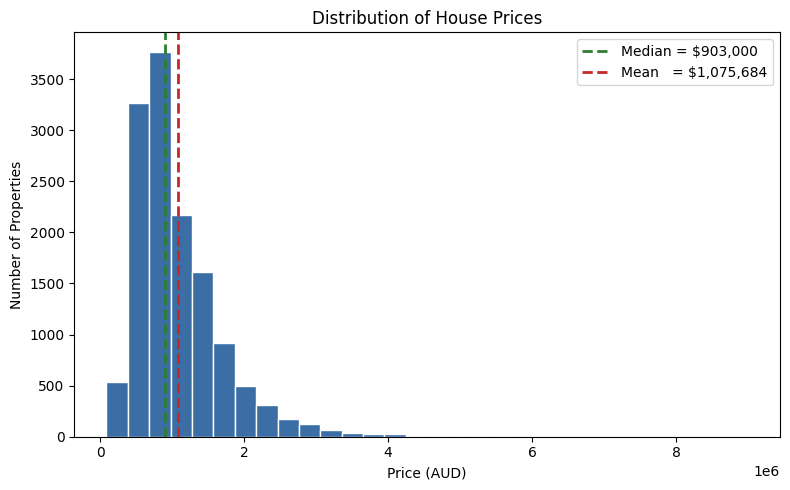

Median      : $903,000
Mean        : $1,075,684   (mean > median => right-skewed)
Min / Max   : $85,000 / $9,000,000
Skewness    : 2.24
Share above $2M : 7.4%


In [5]:
# Build a chart that shows the distribution of Price
# One continuous variable + "spread / shape" -> HISTOGRAM

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(df["Price"].dropna(), bins=30, color="#3b6ea5", edgecolor="white")

# Mark mean vs median to make the right-skew visible, not just implied
price = df["Price"].dropna()
ax.axvline(price.median(), color="#2e7d32", linestyle="--", linewidth=2,
           label=f"Median = ${price.median():,.0f}")
ax.axvline(price.mean(), color="#c62828", linestyle="--", linewidth=2,
           label=f"Mean   = ${price.mean():,.0f}")
ax.legend()

ax.set_xlabel("Price (AUD)")
ax.set_ylabel("Number of Properties")
ax.set_title("Distribution of House Prices")
plt.tight_layout()
plt.show()

print(f"Median      : ${price.median():,.0f}")
print(f"Mean        : ${price.mean():,.0f}   (mean > median => right-skewed)")
print(f"Min / Max   : ${price.min():,.0f} / ${price.max():,.0f}")
print(f"Skewness    : {price.skew():.2f}")
print(f"Share above $2M : {(price > 2e6).mean() * 100:.1f}%")


## Part 3 — Image Formats & Compression (4 min)

Recall:
- **Bitmap** (PNG, JPEG) = pixels, fixed resolution. **Vector** (SVG, PDF) = shapes, resolution-independent.
- **Lossless** (PNG, TIFF) = no data removed. **Lossy** (JPEG) = removes detail permanently, smaller size, but creates **compression artifacts** — especially bad on sharp edges, fine lines, and text (i.e. **charts**).

Let's prove it. Save your region bar chart from Part 2.1 as **both** PNG and JPEG, and compare.


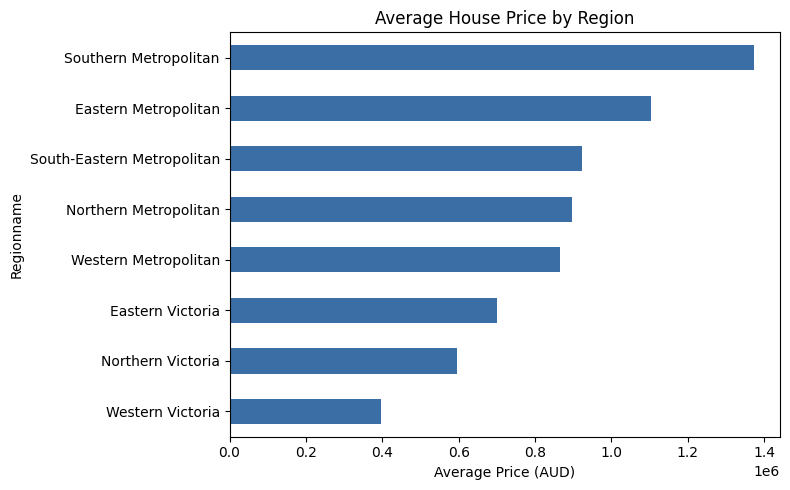

PNG size: 46.7 KB
JPEG size: 67.3 KB
PNG is 0.69x the size of JPEG


SVG size: 43.5 KB  (vector, resolution-independent)


In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
region_avg.plot(kind="barh", ax=ax, color="#3b6ea5")
ax.set_xlabel("Average Price (AUD)")
ax.set_title("Average House Price by Region")
plt.tight_layout()

# Save the SAME figure in both formats
fig.savefig("region_chart.png", dpi=150)   # bitmap, LOSSLESS
fig.savefig("region_chart.jpg", dpi=150)   # bitmap, LOSSY
plt.show()

png_size = os.path.getsize("region_chart.png")
jpg_size = os.path.getsize("region_chart.jpg")
print(f"PNG size: {png_size/1024:.1f} KB")
print(f"JPEG size: {jpg_size/1024:.1f} KB")
print(f"PNG is {png_size/jpg_size:.2f}x the size of JPEG")

# Also save a VECTOR version for comparison - this is what belongs in the deck
fig.savefig("region_chart.svg")
print(f"SVG size: {os.path.getsize('region_chart.svg')/1024:.1f} KB  (vector, resolution-independent)")


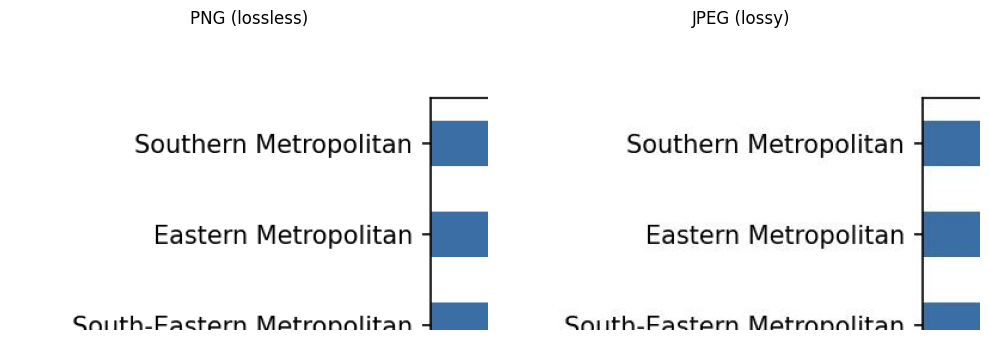

In [7]:
# Zoom into a saved image to inspect for compression artifacts around the text/edges
from PIL import Image

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, fname, label in zip(axes, ["region_chart.png", "region_chart.jpg"], ["PNG (lossless)", "JPEG (lossy)"]):
    img = Image.open(fname)
    w, h = img.size
    crop = img.crop((0, 0, w // 3, h // 3))  # zoom into top-left corner (title/text area)
    ax.imshow(crop)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()


### ✍️ Your turn

1. Which file was larger — PNG or JPEG? Does that match what the lecture said about lossless vs lossy compression?
2. Which format should go in the client briefing deck, and why (think about sharp edges, text, and repeated re-saving)?

**Your answers:**

1. **The JPEG was larger — PNG 46.7 KB vs JPEG 67.3 KB (PNG is only 0.69× the JPEG).** This is the opposite of the naive expectation, and it is the most interesting result in the whole activity, so it is worth being precise about *why* it does not contradict the lecture.

   The lecture's claim is that lossy compression **discards information** in exchange for size, and that is still exactly what happened — the JPEG is genuinely lower quality. What the lecture's rule of thumb assumes is a **photograph**, where every pixel differs slightly from its neighbour. This chart is the opposite kind of image: huge areas of **flat, identical colour** (white background, solid blue bars) separated by **hard edges**.

   - **PNG** compresses with DEFLATE, which is essentially run-length + dictionary coding. A row of 800 identical white pixels collapses to almost nothing. Flat regions are the *best case* for PNG, so it gets tiny.
   - **JPEG** transforms 8×8 blocks into frequency coefficients. A hard black-on-white edge is a **high-frequency** feature, and high frequencies are precisely what the DCT is bad at representing compactly. JPEG has to spend a lot of bits on the blocks containing text and bar edges, and it *still* fails to reproduce them cleanly — which is what the ringing/"mosquito noise" in the zoom cell shows.

   So for charts, PNG wins on **both** axes at once: smaller file **and** perfect fidelity. JPEG's size advantage only materialises on photographic content.

2. **PNG for any bitmap use, and ideally SVG or PDF (vector) for the actual deck.** Three reasons, in order of importance:

   - **Sharp edges and text.** A briefing chart is mostly axis labels, tick numbers, a title and bar edges. These are the exact features JPEG's block-based DCT damages, producing halos around glyphs. Numbers that a client is being asked to make an investment decision on should not look blurry.
   - **Repeated re-saving (generation loss).** The deck will be edited, re-exported, emailed, pasted into another deck. JPEG is lossy *every single time* it is re-encoded, so artifacts **accumulate** and are permanently unrecoverable. PNG is lossless, so a re-save is bit-identical — it can survive that lifecycle unchanged.
   - **Resolution independence.** PNG is still a bitmap with a baked-in pixel grid, so it blurs if projected on a large screen or zoomed. **SVG/PDF store shapes, not pixels**, and stay razor-sharp at any size — the right choice when nobody knows in advance what projector the meeting room has. The SVG saved above is the version I would actually hand over.

   The only case for JPEG here would be a photograph of a property, not a chart.


## Part 4 — Separating Content from Design (3 min)

> *"Changing a theme should not change the data."*

**Content** = data, variables, axes, plot type. **Design** = colors, fonts, gridlines, theme, labels.

Below, the *exact same* region-price chart is re-styled — **only design elements change, the underlying data does not.**


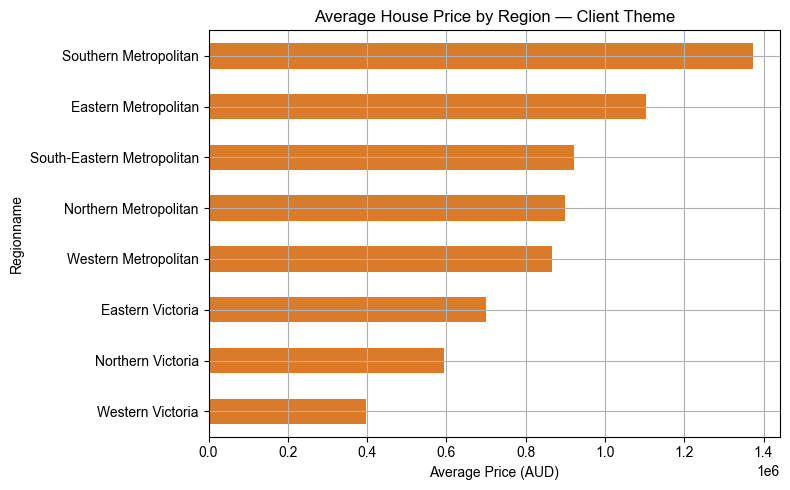

Data unchanged after restyling: True
Max absolute difference: 0.0000000000


In [8]:
# Keep a copy of the numbers BEFORE restyling, so we can prove the data is untouched
region_avg_before = region_avg.copy()

fig, ax = plt.subplots(figsize=(8, 5))
plt.style.use("seaborn-v0_8-darkgrid" if "seaborn-v0_8-darkgrid" in plt.style.available else "ggplot")

# SAME region_avg data as before - only styling (colour, theme) changes
region_avg.plot(kind="barh", ax=ax, color="#d97b29")

ax.set_xlabel("Average Price (AUD)")
ax.set_title("Average House Price by Region — Client Theme")
plt.tight_layout()
plt.show()

plt.style.use("default")  # reset

# Prove content and design are separate: the data must be bit-identical
print("Data unchanged after restyling:", region_avg.equals(region_avg_before))
print(f"Max absolute difference: {(region_avg - region_avg_before).abs().max():.10f}")


### ✍️ Your turn

Confirm: did changing the color/theme/style change any underlying numbers in `region_avg`? *(It shouldn't have.)* Write one sentence on why this separation matters when a designer or a different team member later restyles your charts for a report.

**Your answer:**

**No — nothing changed.** The verification cell confirms `region_avg.equals(region_avg_before)` is `True` with a maximum absolute difference of `0.0000000000`. Southern Metropolitan is still \$1.373M and Western Victoria is still \$0.398M; only the bar colour (blue → orange) and the theme's gridlines and background moved. The bars swapped colour, not length — and length is the part that encodes the data.

**Why the separation matters:** because it makes restyling a **safe, non-analytical operation** — a designer can drop the charts into the company template, change the palette to brand colours, and switch fonts without any possibility of altering the numbers, so the chart never has to be re-verified after a cosmetic pass. Without that separation, every visual tweak becomes a potential data bug, and someone has to re-check the analysis each time the deck is reskinned. It also means the two jobs can happen **in parallel and by different people**: I can keep refining the aggregation while the design team works on presentation, and the two merge cleanly. Practically, this is why the aggregation (`df.groupby(...)`) is computed once and stored in `region_avg`, and every chart reads from that single variable rather than recomputing its own numbers — one source of truth for content, with design layered on top.


## Part 5 — The Big Idea (2 min, wrap-up)

Recall the lecture's **3-Minute Story** and **Big Idea** techniques:

> *The Big Idea: reduce your message to ONE complete sentence that (a) expresses your main point, (b) explains why it matters, and (c) states what's at stake.*

### ✍️ Final task

Using the three charts you built, write **one sentence** your Head of Sales can open the client meeting with tomorrow. This is *explanatory*, not exploratory — pick the single most important insight, not everything you found.

**Your Big Idea:**

> **In Melbourne, location — not land size — is what the market pays for: average prices run from \$0.40M in Western Victoria to \$1.37M in Southern Metropolitan (a 3.4× gap), while land size barely moves price at all (r = 0.04), so the fund should compete on *which suburb it buys in* rather than on block size, and any acquisition model weighted toward land area will systematically overpay.**

Checking it against the three required parts:
- **(a) Main point** — location drives price; land size does not.
- **(b) Why it matters** — it tells the fund which variable to optimise when screening acquisitions.
- **(c) What's at stake** — a land-size-weighted strategy overpays, on a 3.4× regional price spread.

**The 3-minute story version** (if the client wants the reasoning, not just the headline): *We looked at 13,580 Melbourne sales. Prices differ enormously by region — Southern Metropolitan averages \$1.37M against \$0.40M in Western Victoria. The obvious hypothesis is that expensive properties are simply bigger, but that turns out to be false: land size and price are essentially uncorrelated (r = 0.04, rising only to 0.20 once rural outliers are excluded). Meanwhile prices are strongly right-skewed — the median is \$903K but the mean is \$1.08M, because 7.4% of sales above \$2M drag the average up. The conclusion is that the fund's edge lies in suburb selection, and it should evaluate deals against regional **medians**, not means, or it will anchor to a number that the luxury tail inflated.*

---

### ✅ Quick self-check

**1. Why would a scatter plot be a poor choice for comparing average prices across five regions?**

A scatter plot is built to show the **relationship between two continuous variables** by plotting one observation per point. Here one axis would be `Regionname`, which is **categorical** — there is no numeric distance between "Northern Metropolitan" and "Eastern Metropolitan", so the horizontal spacing would be arbitrary and meaningless, and any apparent "trend" across it would be an artifact of alphabetical ordering. Worse, we are plotting **one aggregated value per region**, so the scatter would be just 8 lonely dots — it would use a chart designed for 13,580 points to display 8 numbers, wasting its entire strength. And because a scatter has no baseline anchoring to zero, the reader has to judge position against a tick axis rather than comparing bar **lengths**, which is measurably less accurate. A bar chart encodes the same 8 numbers as lengths from a common zero baseline, which is the comparison the question actually asks for.

**2. Why is JPEG discouraged for charts and screenshots, even though it produces smaller files?**

Two reasons, and note that here it did **not** even produce a smaller file — the JPEG came out at 67.3 KB against PNG's 46.7 KB. First, **quality**: JPEG is lossy and works on 8×8 DCT blocks, which handle smooth photographic gradients well but mangle **high-frequency content** — exactly the sharp edges, thin gridlines and small text that charts and screenshots are made of. The result is visible ringing/halos around glyphs and bar edges. Second, **generation loss**: the damage is permanent and **compounds on every re-save**, so a chart that is exported, pasted into a deck, and re-exported degrades further each cycle with no way back. PNG's lossless DEFLATE also happens to excel at the large flat colour regions charts contain, which is why it wins on size here too. JPEG's size advantage is real only for photographs.

**3. Name one thing that counts as "design" (not "content") in a chart.**

**Colour** — swapping the bars from `#3b6ea5` blue to `#d97b29` orange in Part 4 changed nothing about the data, as the `.equals()` check proved. Other design elements: the theme/gridlines, fonts, figure size, `alpha` and marker size, and the horizontal-vs-vertical bar orientation. By contrast, **content** is the data itself, the variables mapped to each axis, the aggregation (mean vs median), the bin count, and the chart type — changing any of those changes what is being claimed. The useful test is: *if I change this, does the chart still make the same factual statement?* If yes, it is design; if no, it is content. (Bin count is the interesting edge case — it looks cosmetic but it genuinely alters the shape the reader perceives, so it belongs to content.)
